In [80]:
%config InlineBackend.figure_format = "retina"

import seaborn as sns

NEON = [
    "#00F5D4", "#8B5CF6", "#FF4D8D",
    "#FFD166", "#4CC9F0", "#B8F2E6"
]

sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette=NEON,
    font_scale=0.85,
    rc={
        # Keep the same plot dimensions
        "figure.figsize": (15, 5),
        "figure.dpi": 100,
        "savefig.dpi": 300,

        # Dark neon appearance
        "figure.facecolor": "#0B1020",
        "axes.facecolor": "#111827",
        "text.color": "#F8FAFC",
        "axes.labelcolor": "#CBD5E1",
        "axes.titlecolor": "#F8FAFC",
        "xtick.color": "#AAB4C5",
        "ytick.color": "#AAB4C5",

        # Smaller, sharper-looking typography
        "axes.titlesize": 12,
        "axes.titleweight": "semibold",
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,

        # Thin lines and subtle grid
        "lines.linewidth": 1.8,
        "lines.markersize": 4,
        "grid.color": "#334155",
        "grid.alpha": 0.25,
        "grid.linewidth": 0.5,

        # Clean borders and legends
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
    }
)

In [60]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df.job_posted_date)

## Count Of Job titles.

In [ ]:
df.pivot_table(index='job_title_short', aggfunc='size')


job_title_short
Business Analyst              49063
Cloud Engineer                12331
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Machine Learning Engineer     14080
Senior Data Analyst           29216
Senior Data Engineer          44563
Senior Data Scientist         36957
Software Engineer             44929
dtype: int64

In [11]:
df.groupby('job_title_short').size()

job_title_short
Business Analyst              49063
Cloud Engineer                12331
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Machine Learning Engineer     14080
Senior Data Analyst           29216
Senior Data Engineer          44563
Senior Data Scientist         36957
Software Engineer             44929
dtype: int64

In [22]:
df.pivot_table(values='salary_year_avg', index='job_country', columns='job_title_short', aggfunc='median')

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_country,,,,,,,,,,
Albania,NaN,NaN,49950.00,NaN,69981.25,NaN,NaN,NaN,157500.0,NaN
Algeria,NaN,NaN,44100.00,45000.0,NaN,NaN,NaN,NaN,NaN,NaN
Argentina,71100.0,197500.0,92771.75,96773.0,71000.00,101029.0,NaN,147500.0,NaN,174500.0
Armenia,NaN,NaN,100500.00,48750.0,NaN,87021.0,NaN,NaN,NaN,NaN
Australia,70000.0,110000.0,109500.00,106712.5,139216.00,101029.0,50640.0,147500.0,157500.0,118350.0
...,...,...,...,...,...,...,...,...,...,...
Uruguay,NaN,NaN,100500.00,NaN,NaN,50000.0,NaN,NaN,57500.0,NaN
Uzbekistan,NaN,NaN,NaN,NaN,30750.00,NaN,NaN,NaN,NaN,NaN
Vietnam,79200.0,NaN,75550.00,96773.0,70000.00,57600.0,105837.5,147500.0,79200.0,53600.0


## Top Contires salaryies info for data jobs.

<Axes: title={'center': 'Top contries with there "Data" Jobs salaries'}, ylabel='Median Salary ($USD)'>

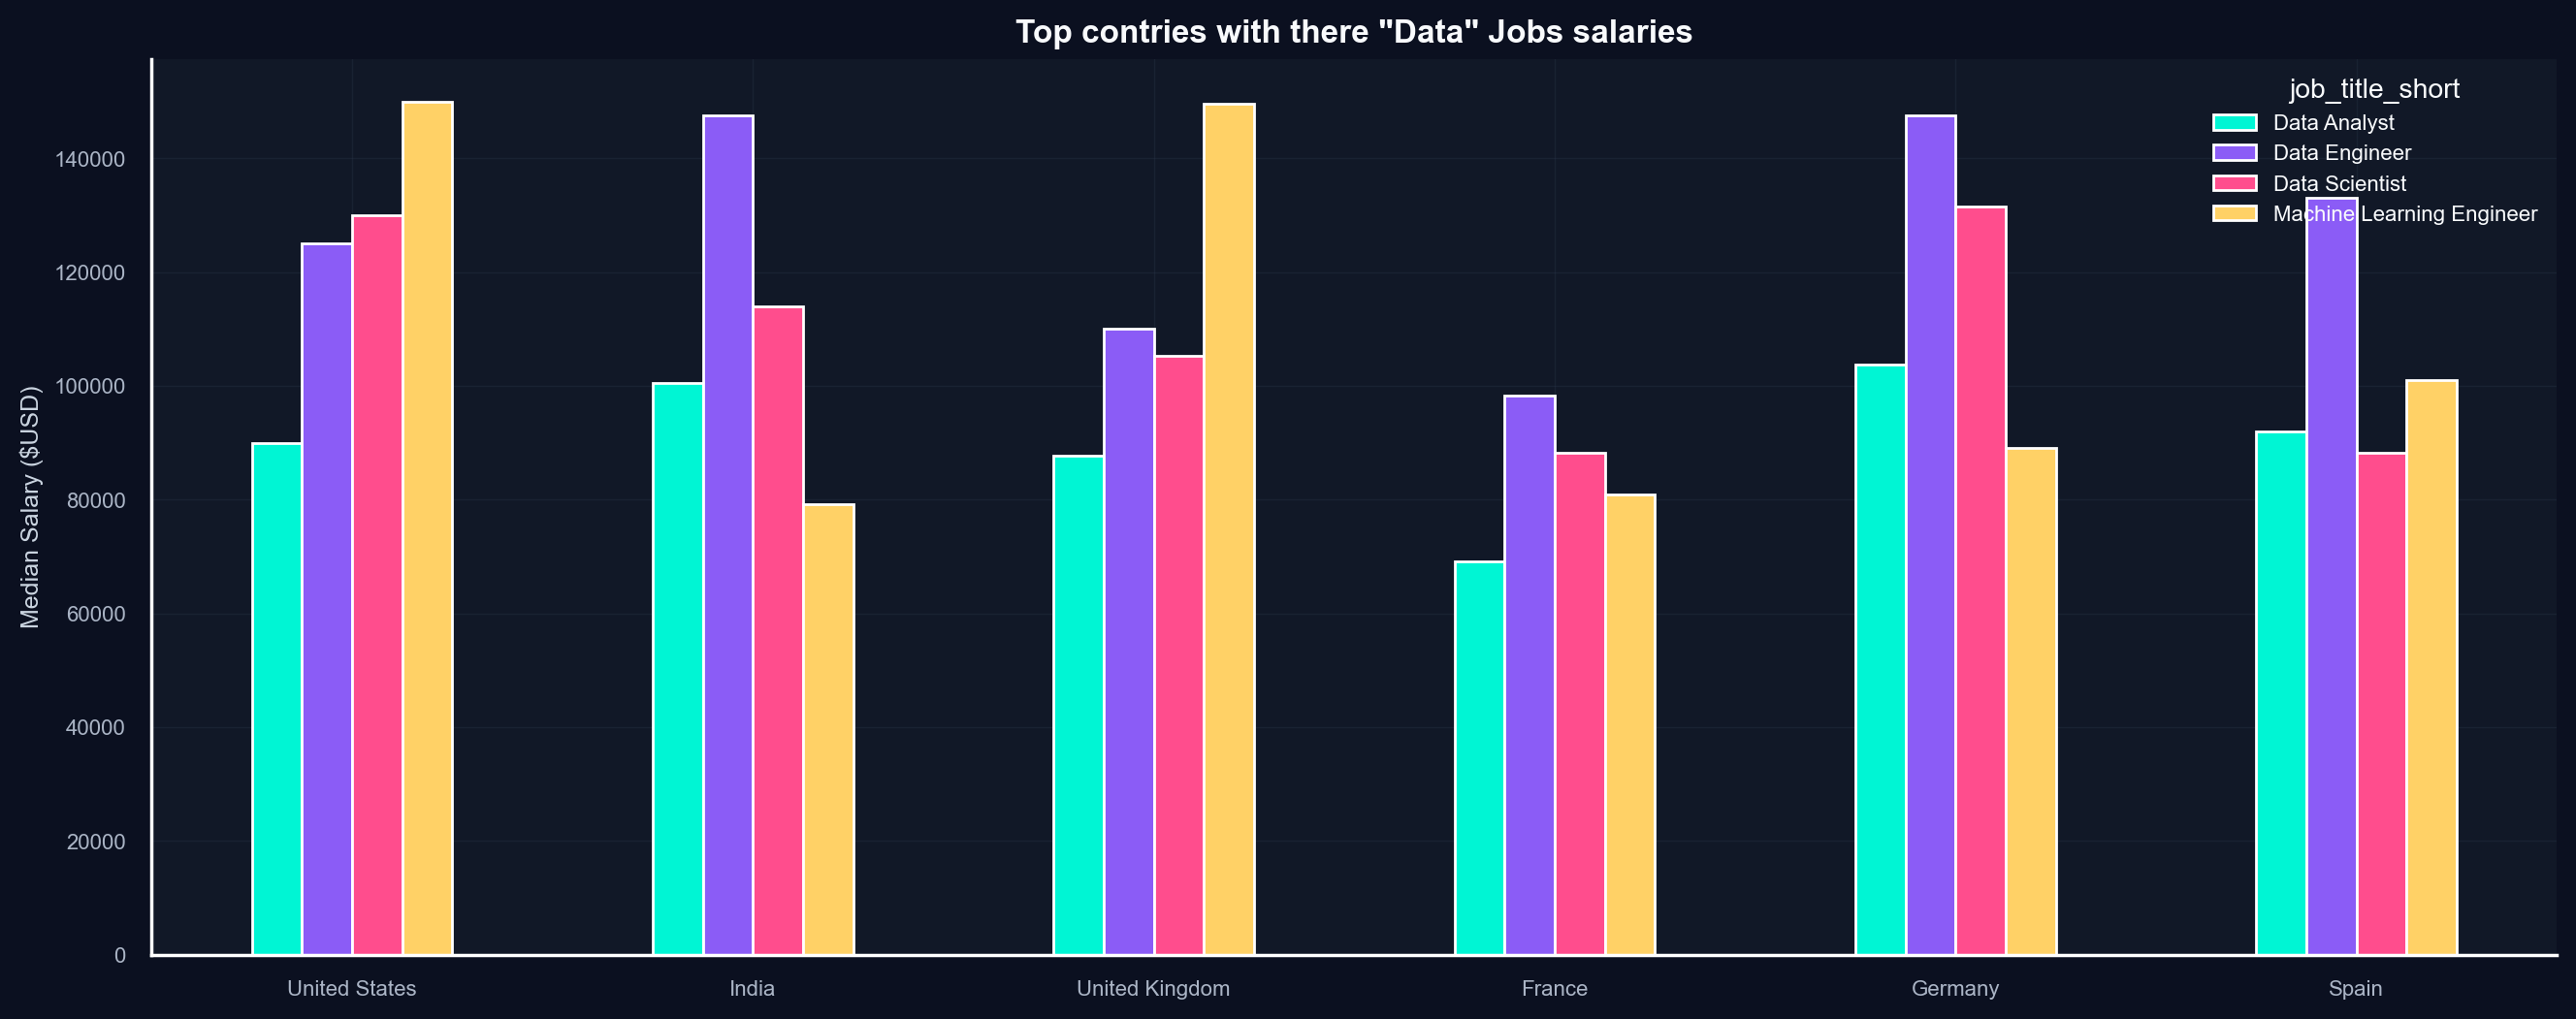

In [107]:
top_countries = df['job_country'].value_counts().head(6).index

job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist', 'Machine Learning Engineer']

df_job_contries_salaries = df.pivot_table(
    values= 'salary_year_avg',
    index='job_country',
    columns= 'job_title_short',
    aggfunc='median'
).loc[top_countries]

df_job_contries_salaries = df_job_contries_salaries[job_titles]

df_job_contries_salaries.plot(
    title='Top contries with there "Data" Jobs salaries',
    kind='bar',
    xlabel='',
    ylabel='Median Salary ($USD)',
    rot=0,
    figsize=(16, 6)
)

